# <center>CITS5508 Assignment 1</center>
<center><b>Jason Wang</b></center>
<center><b>24839132</b></center>

# I. Introduction

This assignment will investigate two machine learning models, Softmax Regression and Support Vector Machine Regression, which applies classification and regression tasks respectively. In part 1, we will implement a Softmax Regression from scratch using batch gradient descent and compare it against scikit learn's implementation of Softmax Regression, we will implement these two models onthe MNIST dataset. In part 2, we will first create a toy polynomial dataset function to create several datasets and explore how different SVM kernels fit the different polynomial degree of dataset. After, we will implement GridSearchCV to tune the hyperparameters and find optimal hyperparameters to configure our model to fit well on a cubic dataset and evaluate the performance using appropriate metrics and discuss our findings.

# II. Methodology

## Part 1: Softmax Regression
For this section the MNIST dataset was laoded from Open ML using scikit-learn and by converting the labels into integer values. The data was split into 70% training, 15% validation and 15% testing, using random sampling as the data is well distributed across all classes. We then implement a Softmax Regression classifier from scratch using Numpy. This from scartch model uses a cross-entropy loss and vectorised gradient descent to train the model. Training was also monitored by using both training and validation loss and an early stopping function was applied when validation loss stopped improving. We then use scikit-learn's LogisticRegression function to fit a Softmax Regression. We then evaluate the two models using accuracy, confusion matrices, precision, recall and ROC-AUC.

## Part 2: SVM Regression
We first wrote a function to generate a synthetic polynomial datasets. We then use this function to populate 3 datasets(linear, quadratic and cubic) and split each one of them into a train and test set. Next, for each data set we train SVM regression models using linear, polynomial and RBF kernels to compare how each kernels captures the underlying datasets. Lastly, we take the cubic dataset and a grid search with 5 fold cross validation was used on an SVM regression model over several hyperparameters. The model was then selected and evaluated onthe test set using the Mean Squared Error and a visual plot of the fitted curve.

In [1]:
# importing the functions
import pandas as pd
import numpy as np
import time as tm
import matplotlib as mpl
import matplotlib.pyplot as plt

# to display plots in Jupyter notebook
%matplotlib inline
plt.rcParams['font.size'] = '12'

# Part 1 Softmax Regression

## 1. Load the MNIST dataset from OpenML using scikit-learn:

To load the MNIST dataset, we will need to import a function from the sklearn datasets library. After loading it in, we will look into the data types and shapes.

In [2]:
# import sklearn dataset
from sklearn.datasets import fetch_openml

# Loading the MNIST dataset
X, y = fetch_openml("mnist_784", version=1, return_X_y=True, as_frame=False)

In [3]:
X.dtype

dtype('int64')

In [4]:
y.dtype

dtype('O')

We can see that the data type for the y variable is in object and not numeric. We will need to convert them into integer type. The reason is that most machine learning models require the class labels to be in integer type. Also, in numpy and python, labels are often sliced or passed to functions that expect integers. If y remains as a string or object, certain operations can fail or produce incorrect results. Thus, converting ensures compatibaility with certain computations and ML algorithms.

In [5]:
y = y.astype(int)
y.dtype

dtype('int32')

## 2. Display some examples from the dataset. Describe what the features and labels represent.

In [6]:
X.shape

(70000, 784)

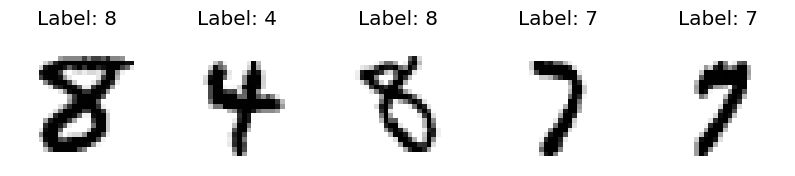

In [7]:
# random seed for reproducibility
np.random.seed(42)
# selecting 5 random instances from the dataset
number_samples = 5
indices = np.random.choice(X.shape[0], number_samples, replace = False)
# plotting the selected images
plt.figure(figsize=(10, 2))
for i, index in enumerate(indices):
    image = X[index].reshape(28,28) # reshaping the flat vector into a 28*28 image
    label = y[index] # the corresponding label

    plt.subplot(1, number_samples, i+1)
    plt.imshow(image, cmap='binary')
    plt.title(f"Label: {label}")
    plt.axis('off')

plt.show()

The MNIST dataset contains hand writen numbers and their labeled numbers. Upon checking the shape, we can see that there are 70,000 images and each image has 784 features. This is because each image is in 28x28 pixels, and each feature represents one pixel's intensity, from 0(white) to 255(black). Their corresponding labels in y indicate the actual digit the image represents, ranging from 0 to 9. Such as, a label of 5, means the image pixels is a handwritten 5. We sampled a few images and their respective labels to visually confirm that the data has been loaded correctly and that the features are corresponding to the correct digit label.

## 3. Split the dataset into a training, validation, and test set. You should use 70% of the data for training, and 15% for validation, and 15% for testing.

In [8]:
# import train_test_split from sklean library
from sklearn.model_selection import train_test_split
# splitting the dataset into 70% of the data for training, and 15% for validation, and 15% for testing
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=42)

### (a) Display the class distribution in the training, validation and test sets.

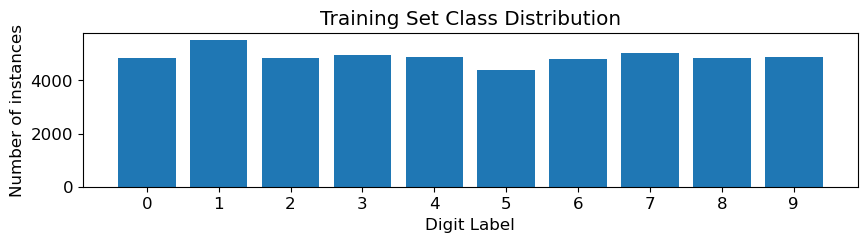

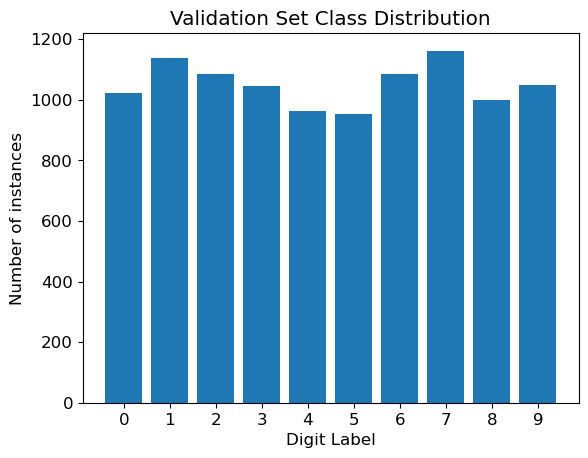

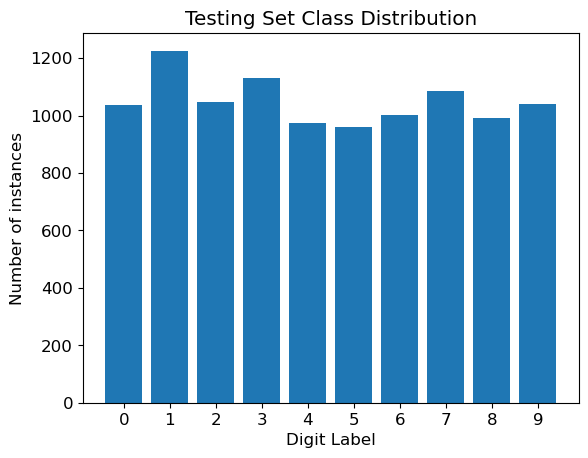

In [9]:
# function to display the distribution of each class
def plot_distribution(y, title):
    classes, counts = np.unique(y, return_counts=True)
    plt.bar(classes, counts)
    plt.xticks(classes)
    plt.xlabel('Digit Label')
    plt.ylabel('Number of instances')
    plt.title(title)
    plt.show()
# display the class distribution for training, validation and test sets
plt.figure(figsize=(10, 2))
plot_distribution(y_train, 'Training Set Class Distribution')
plot_distribution(y_val, 'Validation Set Class Distribution')
plot_distribution(y_test, 'Testing Set Class Distribution')

### (b) Do you need to stratify your split? Why or why not?

Based on the distribution of classes across the different sets, we can see that each class is well balanced, with each class having similar numbers of instances. This suggests that not one particular class is being underrepresented so we don't need to apply stratified sampling, since the main reason we would use stratified sampling is to ensure each split preserves the original class proportions, which helps the model to perform and generalise consistently across all of the classes. But, since the plot above suggests that the MNIST dataset is well balanced for each class given the large dataset, the randomly splitting method will naturally preserve class proportions. However, stratified splitting can still be applied as a precaution to ensure consistent class distribution. Since, the dataset is well distributed, not a smaller and not imbalanced, random splitting the dataset is already optimal.

## 4. Implement softmax regression with gradient descent using vectorised NumPy code. Implement early stopping based on the validation set. Do not use scikit-learn for this task – only NumPy and basic Python.

The Softmax regression is a generalisation of the logistic regression to the multiclass case. It estimates the probability of class k using:
<center>$$ \hat{p}_k = \frac{\exp(s_k(x))}{\sum{^k}_{j=1}{\exp(s_j(x))}}$$</center>
where K is the total number of classes and $s_k(x) = (\theta^k)^Tx$<br>
The cost function(Cross Entropy Loss) is defined as:
<center>$$ J(\theta) = -\frac{1}{m} \sum{^m}_{i=1}\sum{^K}_{k=1}y^{(i)}_klog(\hat{p}_k) $$</center>
where $ y^{(i)}_k $ is the target probability that the $i^{th}$ instance belongs to class k. Then $ \partial{J}/\partial{\theta^{(k)}}$ is given as:
$$ \frac{\partial{J}}{\partial{\theta^{(k)}}} = \frac{1}{m} \sum{^m}_{i=1} (\hat{p}_k^{(i)} - y_k^{(i)}) x^{(i)}$$
We write the code as follows:

In [10]:
# creating class to hold the entire function
class Manual_SoftMax:
    # initialize the learning rate, iteration and patience value that will break the early stopping code
    def __init__(self, l_rate = 0.01, n_epochs=1000, patience=10, tol=1e-4):
        np.random.seed(42)
        self.l_rate = l_rate
        self.n_epochs = n_epochs
        self.patience = patience
        self.tol=tol
        self.loss = [] # record the training loss
        self.val_loss = [] # record validation loss
    # convert labels into a one-hot encoded matrix
    def one_hot(self, y, K):
        m = len(y)
        Y_onehot = np.zeros((m, K))
        Y_onehot[np.arange(m), y] = 1
        return Y_onehot
    # compute class scores
    def compute_scores(self, X):
        scores = X @ self.Weights
        return scores
    # apply softmax function to convert the scores into probabilities
    def softmax_func(self, scores):
        score = scores - np.max(scores, axis = 1, keepdims = True)
        exp_scores = np.exp(score)
        proba = exp_scores/np.sum(exp_scores, axis = 1, keepdims = True)
        return proba
    # the cross-entropy loss
    def cross_entropy_loss(self, Y, proba):
        m = len(Y)
        loss = -(1/m) * np.sum(Y * np.log(proba + np.finfo(float).eps))
        return loss
    # compute gradient of the loss
    def soft_max_grad(self, X, Y, proba):
        m = len(X)
        diff = proba - Y
        grad = (1/m) * (np.dot(X.T, diff))
        return grad
    # fit the model using gradient descent and early stopping
    def fit(self, X, y, X_val=None, y_val=None):
        # add a bias term
        X = np.hstack([X, np.ones((X.shape[0], 1))])
        if X_val is not None:
            X_val = np.hstack([X_val, np.ones((X_val.shape[0], 1))])
            
        m, n = X.shape
        K = len(np.unique(y))
        Y_onehot = self.one_hot(y, K)
        self.Weights = np.zeros((n, K))
        
        if y_val is not None:
            y_val_onehot = self.one_hot(y_val, K)
        # early stopping variables
        best_val_loss = float('inf')
        best_weights = None
        curr = 0
        #forward pass
        for epoch in range(self.n_epochs):
            scores = self.compute_scores(X)
            proba = self.softmax_func(scores)
            # gradient descent update
            grad = self.soft_max_grad(X, Y_onehot, proba)
            self.Weights -= self.l_rate*grad
            # record the training loss
            scores = self.compute_scores(X)
            proba = self.softmax_func(scores)
            self.loss.append(self.cross_entropy_loss(Y_onehot, proba))
            # skips validation if not provided
            if X_val is None or y_val is None:
                continue
            # compute validation loss
            val_score = self.compute_scores(X_val)
            val_proba = self.softmax_func(val_score)
            val_loss = self.cross_entropy_loss(y_val_onehot, val_proba)
            self.val_loss.append(val_loss)
            # early stopping
            if val_loss < best_val_loss:
                if abs(best_val_loss - val_loss) < self.tol: # if the change is too small
                    print(f'Early stopping at epoch{epoch} - loss change below tolerance')
                    break
                best_val_loss = val_loss
                best_weights = self.Weights.copy()
                curr = 0
            else:
                curr += 1

            if curr >= self.patience:
                print(f'Early stopping at epoch {epoch} - exceeded patience')
                break
        # restore the best weights
        if best_weights is not None:
            self.Weights = best_weights
    # predict_class probabilities
    def predict_proba(self, X):
        X = np.hstack([X, np.ones((X.shape[0], 1))])
        scores = self.compute_scores(X)
        return self.softmax_func(scores)
    # predict class labels
    def predict(self, X):
        proba = self.predict_proba(X)
        return np.argmax(proba, axis = 1)

The MNIST data set features range from 0-255, each representing a pixel, this will make the gradient descent unstable and slow. Thus, we will divide it by 255 so all features will be in similar scales and stabalize the gradient descent function.

In [11]:
# feature scaling()
X_train = X_train/255.0
X_val = X_val/255.0
X_test = X_test/255.0

In [12]:
# call and train the model
Manual = Manual_SoftMax(l_rate=0.1, n_epochs=1000)
Manual.fit(X_train, y_train, X_val, y_val)

Early stopping at epoch667 - loss change below tolerance


### (a) Display a plot showing how the training and validation loss changes over time for your model.

Text(0.5, 1.0, 'Training vs Validation Loss Changes')

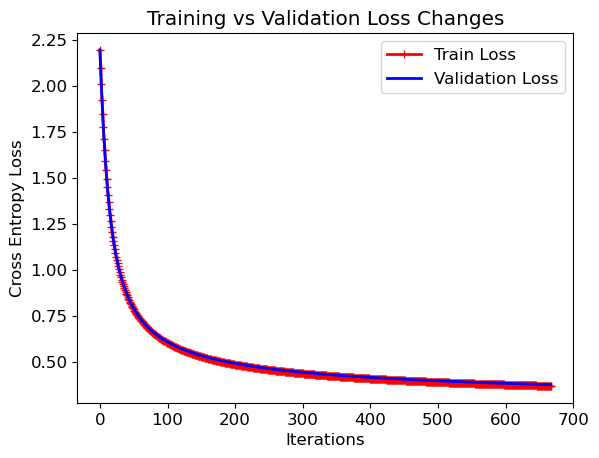

In [13]:
# plotting the training and validation loss
epochs = range(len(Manual.val_loss))
plt.plot(Manual.loss[:len(epochs)], 'r-+', linewidth=2, label='Train Loss')
plt.plot(Manual.val_loss, 'b-', linewidth=2, label='Validation Loss')
plt.legend()
plt.xlabel('Iterations')
plt.ylabel('Cross Entropy Loss')
plt.title('Training vs Validation Loss Changes')

### (b) What do you observe? Is this what you expected?

From iteration 0, both train and validation loss started at a high Cross Entropy Loss, suggesting they are just starting to learn from the data. Then it started to lower the cost function and it visibly started to dip down around the 100th iteration and they both reached the minimum around the 667th iteration. We can see that the train and validation loss are following a similar trend, suggesting the model is not overfitting or underfitting the data, suggesting it generalizes pretty well.

Yes, this is mostly what I would expect. Given that we used gradient descent in fitting the model, I would expect the manual SoftMax Regression code to tweak the parameters till is minimizes the cost function(Cross Entropy Loss), which the graph has shown it has, since it has reached the minimum at somewhere near the 667th epoch. Also, since we have implemented an early stopping function, it should halt training once validation error reaches at a minimum, which it has as the graph stops populating at around 667th epoch.

## 5. Fit a sklearn.linear model.LogisticRegression model to the data. Do not apply regularisation. Compare the performance of your softmax regression model to the scikit-learn model.

In [14]:
# import sklearn's logistic regression
from sklearn.linear_model import LogisticRegression
# call and train the model
sm_model = LogisticRegression(solver="lbfgs", max_iter=10000, random_state=42, penalty = None)
sm_model.fit(X_train, y_train)

LogisticRegression(max_iter=10000, penalty=None, random_state=42)

Given the features are ranged from 0-255, I have decided to apply standard scaling first, since for machine learning algorithms, unscaled data can lead to long run time, more iterations, and it will take longer for the softmax regression to converge. I displayed the confusion matrix between the two model for all the dataset splits to show how the manual model performs and generalizes against the scikit learn's softmax regression. We run the model in scikit learn's and display the confusion matrix as follows:

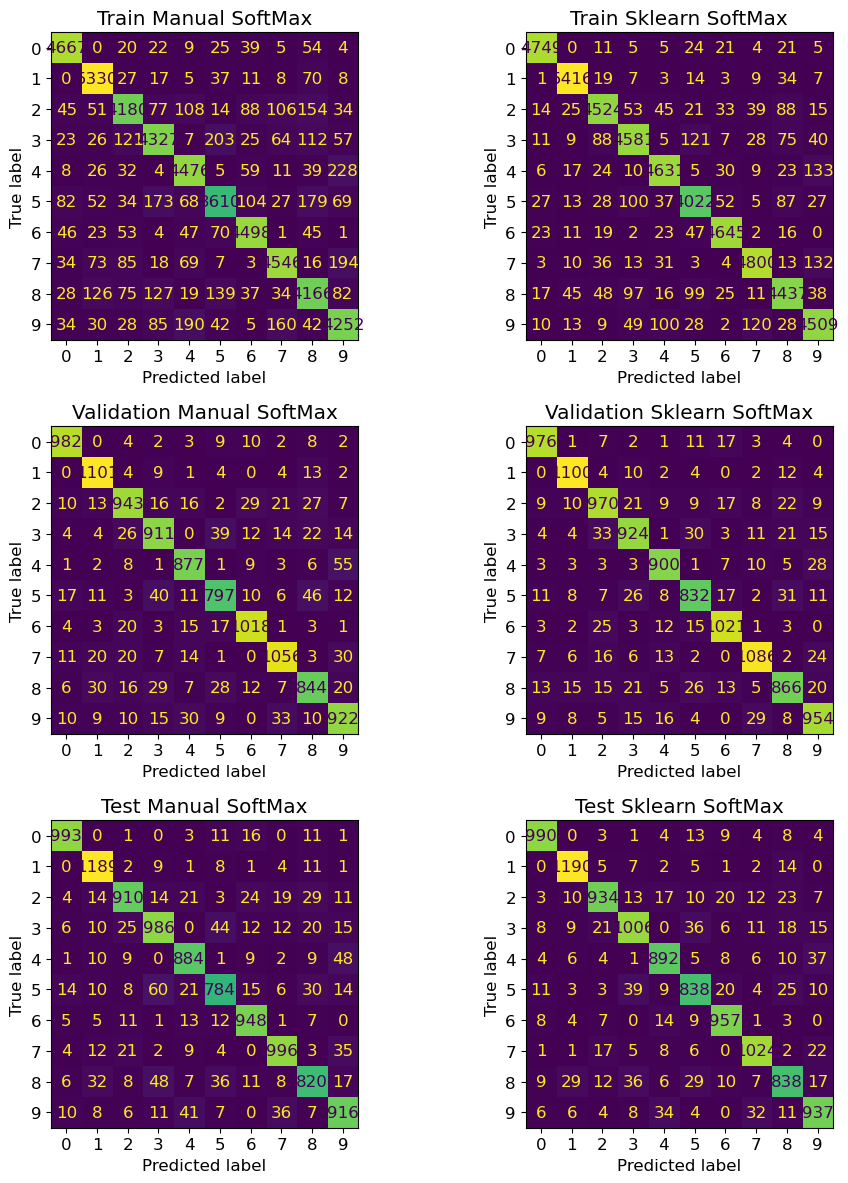

In [15]:
# importing the confusion_matrix and ConfusionMatrixDisplay functions
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
def confusion_matrixplots(y, y_pred, title, axis):
    cm = confusion_matrix(y, y_pred)
    display = ConfusionMatrixDisplay(cm)
    display.plot(ax=axis, colorbar=False)
    axis.set_title(title)

# prediction on train set
y_pred_train_manual = Manual.predict(X_train)
y_pred_train_sklearn = sm_model.predict(X_train)

# prediction on validation set
y_pred_val_manual = Manual.predict(X_val)
y_pred_val_sklearn = sm_model.predict(X_val)

# prediction on test set
y_pred_test_manual = Manual.predict(X_test)
y_pred_test_sklearn = sm_model.predict(X_test)

# plotting confusion matrices for all splits
fig, axes = plt.subplots(3, 2, figsize=(10,12))
confusion_matrixplots(y_train, y_pred_train_manual, 'Train Manual SoftMax', axes[0][0])
confusion_matrixplots(y_train, y_pred_train_sklearn, 'Train Sklearn SoftMax', axes[0][1])
confusion_matrixplots(y_val, y_pred_val_manual, 'Validation Manual SoftMax', axes[1][0])
confusion_matrixplots(y_val, y_pred_val_sklearn, 'Validation Sklearn SoftMax', axes[1][1])
confusion_matrixplots(y_test, y_pred_test_manual, 'Test Manual SoftMax', axes[2][0])
confusion_matrixplots(y_test, y_pred_test_sklearn, 'Test Sklearn SoftMax', axes[2][1])
plt.tight_layout()
plt.show()

The diagonals of the confusion matrix displays correct classsifications. We can see that the scikit learn's model was able to classify the labels better than the manual model. While the off diaganols display the models misclassification. We can see that the scikit learns has lower misclassification compared to our manual model. For example, sklearn's LogisticRegression was able to predict more 1's correctly in the train set (4667 vs 4749), but the manual sofmax function performs slightly better in the validation and test splits(982, 993 vs 976, 990). However, when we look at how it predicts 9, we can see that the sklearn logistic regression was able to predict more accurateley(4509, 954, 937) compared to our manual implementation of softmax(4252, 922, 916). Suggesting the two models being able to predict certain classes much better than the other, but overall as we look into every prediction along the diaganol, we can see that sklearn's overall predictions are more accurate compared to the manual softmax function. We can also see that for the two models, the validation and test set follow a similar classification and misclassification pattern, suggesting both are generalizing well, thus the two models are not overfitting or underfitting the data. This overall sugests our manual model is implemented correctly and is behaving similarly to scikit learn's logistic regression.

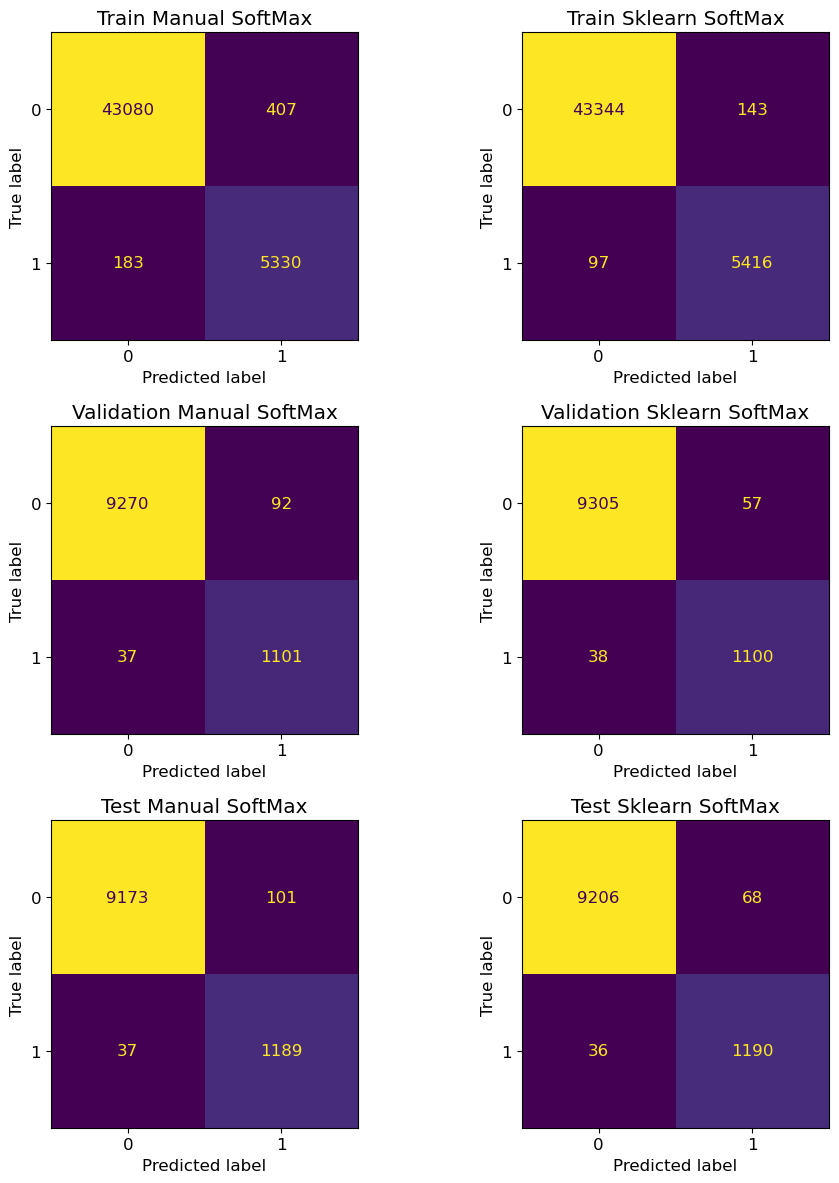

In [16]:
# plot confusion matrices for 1 vs not 1's for all splits
fig, axes = plt.subplots(3, 2, figsize=(10,12))
confusion_matrixplots(y_train==1, y_pred_train_manual==1, 'Train Manual SoftMax', axes[0][0])
confusion_matrixplots(y_train==1, y_pred_train_sklearn==1, 'Train Sklearn SoftMax', axes[0][1])
confusion_matrixplots(y_val==1, y_pred_val_manual==1, 'Validation Manual SoftMax', axes[1][0])
confusion_matrixplots(y_val==1, y_pred_val_sklearn==1, 'Validation Sklearn SoftMax', axes[1][1])
confusion_matrixplots(y_test==1, y_pred_test_manual==1, 'Test Manual SoftMax', axes[2][0])
confusion_matrixplots(y_test==1, y_pred_test_sklearn==1, 'Test Sklearn SoftMax', axes[2][1])
plt.tight_layout()
plt.show()

I decided to check the confusion matrix in more detail, comparing 1 vs not 1, we can see that both the manual and the sklearn model are able to generalize well and still follow a similar pattern to the train set, which supports our findings that the model is not overfitting or underfitting. We can see that the manual model is behaving similarly to the scikit learn model. Thus, we can conclude that the manual model has been implemented correctly, but the scikit learn's model is still better at generalizing compared to our manual model, given that the scikit learn's have higher true positives and true negatives and lower false positives and false negatives compare to the manual model. This is to be expected, since the scikit learn's version is using a more optimized algorithm and applying a more stabalized method in computing, giving us a more precise model.

### (b) Show appropriate evaluation metrics for both models.

In [17]:
# import the metrics to be used
from sklearn.metrics import accuracy_score, precision_recall_curve, f1_score
# function to solve the optimal precision recall
def optimal_metrics(precision, recall, thresholds):
    f1_scores = 2 * (precision  * recall) / (precision + recall + np.finfo(float).eps)
    idx = np.argmax(f1_scores)
    optimal_threshold = thresholds[idx]
    print(f'optimal F1: {f1_scores[idx]:.3f} (precision: {precision[idx]:.3f}, recall: {recall[idx]:.3f})')
# function to plot the precision recall curve
def plot_precision_recall(m_precision, m_recall, sk_precision, sk_recall):
    plt.figure(figsize=(8, 6))
    plt.plot(m_precision, m_recall, color = 'red', label = 'Manual SoftMax')
    plt.plot(sk_precision, sk_recall, color = 'blue', label = 'Sklearn SoftMax')
    plt.title('Test set')
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.legend()
    plt.show()

#accuracy scores and printing the accuracy scores
manual_acc = accuracy_score(y_test, y_pred_test_manual)
sklearn_acc = accuracy_score(y_test, y_pred_test_sklearn)
print('The accuracy score for the manual SoftMax is:', manual_acc)
print('The accuracy score for the sklearn SoftMax is:', sklearn_acc)

The accuracy score for the manual SoftMax is: 0.8977142857142857
The accuracy score for the sklearn SoftMax is: 0.9148571428571428


We first populate the accuracy score for the manual softmax and sklearn's logistic regression. We see that our manual softmax has an accuracy of 0.8977, while the sklearn's softmax is 0.9149. Eventhough both have fairly high and close accuracy scores, the sklearn logistic regression was able to predict classes with slightly more accurately compared to the manual softmax. This is to be expected, since Sklearn's uses a more sophisticated optimiazation function compared to the gradient descent of our manual softmax. It should also be noted, given the classes are balanced, with no one class dominating over the others, accuracy is a reliable metric for this. We would normally avoid accuracy if the classes were imbalanced, since it causes the model to predict the majority class, which causes accuracy score to be misleading.

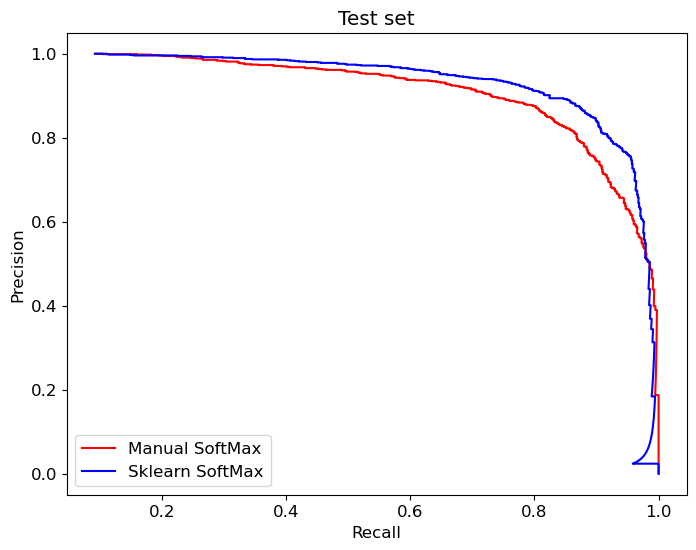

optimal F1: 0.839 (precision: 0.857, recall: 0.822)
optimal F1: 0.874 (precision: 0.873, recall: 0.874)


In [18]:
# plot and print manual softmax precision recall and optimal precision recall numbers
m_precision, m_recall, m_thresholds = precision_recall_curve(y_test==5, Manual.predict_proba(X_test)[:, 5])
sk_precision, sk_recall, sk_thresholds = precision_recall_curve(y_test==5, sm_model.predict_proba(X_test)[:, 5])
plot_precision_recall(m_precision, m_recall, sk_precision, sk_recall)
optimal_metrics(m_precision, m_recall, m_thresholds)
optimal_metrics(sk_precision, sk_recall, sk_thresholds)

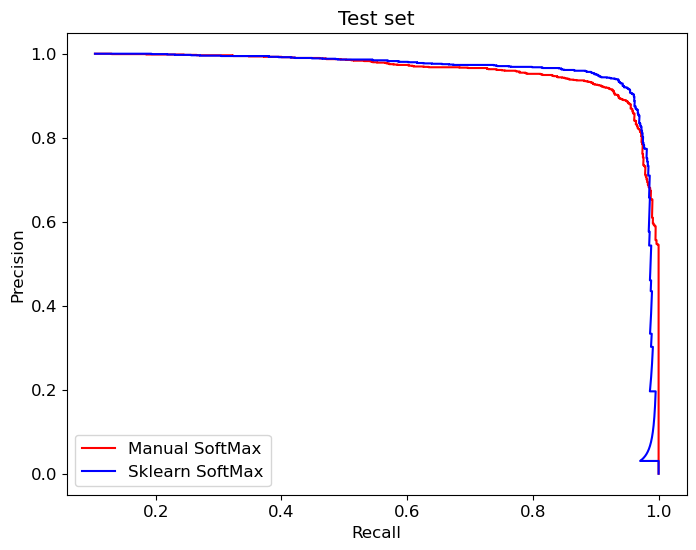

optimal F1: 0.921 (precision: 0.926, recall: 0.915)
optimal F1: 0.937 (precision: 0.936, recall: 0.939)


In [19]:
# plot and print sklearn's logistic regression precision recall and optimal precision recall numbers
m_precision, m_recall, m_thresholds = precision_recall_curve(y_test==7, Manual.predict_proba(X_test)[:, 7])
sk_precision, sk_recall, sk_thresholds = precision_recall_curve(y_test==7, sm_model.predict_proba(X_test)[:, 7])
plot_precision_recall(m_precision, m_recall, sk_precision, sk_recall)
optimal_metrics(m_precision, m_recall, m_thresholds)
optimal_metrics(sk_precision, sk_recall, sk_thresholds)

I've decided to look into the precision and recall of the manual model and sklearn model. The first plot I checked the models on how it predicts 5 vs non-5s.  we can see that the manual one has a precision of 0.857 and recall of 0.822, while the sklearn has a precision of 0.873 and recall of 0.874. This suggests that the manual model predicts a 5, 85.7% of these are actually 5, out of all actual 5, 82.2% are correctly predicted as 5. While the sklearn model predicts a 5, 87.3% of these are actually 5, out of all actual 5, 87.4% are correctly predicted as 5. We can see that the skleran logistic regression model has a higher score in both precision and recall compared to the manual softmax model, and has a more balanced f1-score(0.874) compared to the manual sofmax model(0.851), it seems the sklearn's logistic regression is better and more balanced in distinguishing 5 and non-5 compared to out manual softmax function.

To support this, I plotted another plot to check how the model classifies 7 vs non-7. we can see that the manual one has a precision of 0.926 and recall of 0.915, while the sklearn has a precision of 0.936 and recall of 0.939. This suggests that the manual model predicts a 7, 92.6% of these are actually 7, out of all actual 7, 91.5% are correctly predicted as 7. While the sklearn model predicts a 7, 93.6% of these are actually 7, out of all actual 7, 93.9% are correctly predicted as 7. Similar to when the model is predicting 5, the sklearn has a better balance in distinguishing 8, given the fi-score(0.937), compared to the manual model(0.921). This supports the findings that sklearn's logistic regression is overall better in distinguishing classes compared to the manual softmax function.

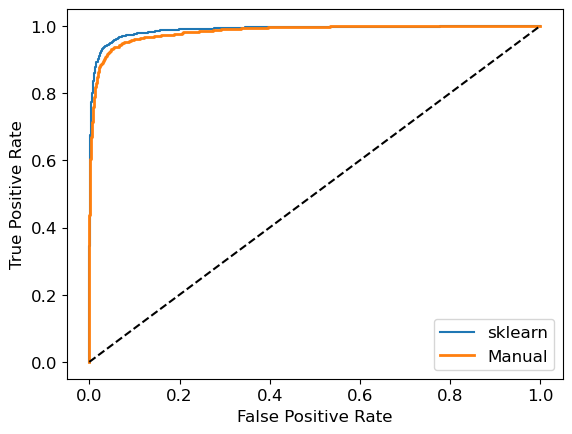

The ROC-AUC for the manual model is 0.9831406401966268
The ROC-AUC for scikit-learns model is 0.988227307424204


In [20]:
# import functions for roc-auc
from sklearn.metrics import roc_curve, roc_auc_score
# function to plot auc_roc
def plot_roc_curve(fpr, tpr, label=None):
    plt.plot(fpr, tpr, linewidth=2, label=label)
    plt.plot([0, 1], [0, 1], 'k--')

# manual softmax for 5 vs non 5
m_fpr, m_tpr, m_thresholds = roc_curve(y_test==5, Manual.predict_proba(X_test)[:, 5])
m_roc_auc = roc_auc_score(y_test==5, Manual.predict_proba(X_test)[:, 5])

# sklearn logistic regression for 5 vs non 5
fpr, tpr, thresholds = roc_curve(y_test==5, sm_model.predict_proba(X_test)[:, 5])
roc_auc = roc_auc_score(y_test==5, sm_model.predict_proba(X_test)[:, 5])
# plot the roc-auc for both manual and sklearn's logistic regression
plt.plot(fpr, tpr, label = 'sklearn')
plot_roc_curve(m_fpr, m_tpr, 'Manual')
plt.ylabel('True Positive Rate')
plt.xlabel('False Positive Rate')
plt.legend(loc='lower right')
plt.show()
# print the roc_auc of the 2 models
print('The ROC-AUC for the manual model is', m_roc_auc)
print('The ROC-AUC for scikit-learns model is',roc_auc)

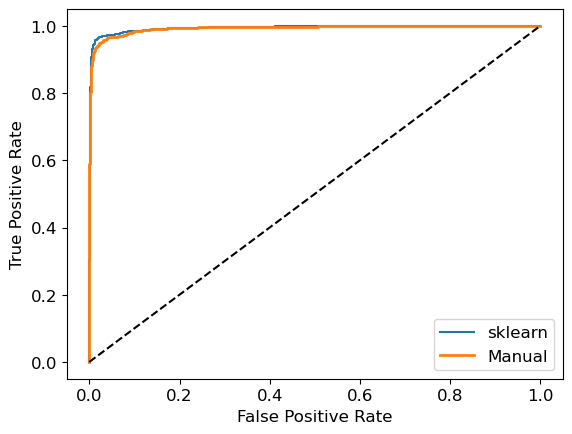

The ROC-AUC for the manual model is 0.9928777562198222
The ROC-AUC for scikit-learns model is 0.9940702906724478


In [21]:
# manual softmax for 7 vs non 7
m_fpr, m_tpr, m_thresholds = roc_curve(y_test==7, Manual.predict_proba(X_test)[:, 7])
m_roc_auc = roc_auc_score(y_test==7, Manual.predict_proba(X_test)[:, 7])

# sklearn softmax for 7 vs non 7
fpr, tpr, thresholds = roc_curve(y_test==7, sm_model.predict_proba(X_test)[:, 7])
roc_auc = roc_auc_score(y_test==7, sm_model.predict_proba(X_test)[:, 7])
# plot the roc-auc for both manual and sklearn's logistic regression
plt.plot(fpr, tpr, label = 'sklearn')
plot_roc_curve(m_fpr, m_tpr, 'Manual')
plt.ylabel('True Positive Rate')
plt.xlabel('False Positive Rate')
plt.legend(loc='lower right')
plt.show()
# print the roc_auc of the 2 models
print('The ROC-AUC for the manual model is', m_roc_auc)
print('The ROC-AUC for scikit-learns model is',roc_auc)

Another metric I decded to check is the AUC-ROC, this shows how well a model sperates classes from one another. A higher ROC indicates the model is better at identifying True Postives and False Positives. The ROC score for when the model is classifying 5 vs non-5 shows that the sklearn has a is better in distinguishing given the roc score(0.9882) compared to the manual softmax(0.9831), similarly when the model is classifying 7 vs non-7 shows the sklearn logistic regression(0.9947) is slightly better in distinguishing compared to the manual softmax(0.9929). The ROC-AUC plot support this as the sklearn logistic regression has a slightly larger AUC compared to the manual softmax. Thus, suggesting the sklearn's softmax is the overall better model to generalize this dataset compared to the manual softmax function.

### (c) Comment on the results. Are they what you expected? Why or why not?

The overall results show that sklearn softmax is better in multi-classification tasks compared to the manual softmax function. This is fully supported by the performance metrics on the test set. The accuracy scores show that sklearn is better in overall correct predictions given the higher score (0.9149 vs 0.8977). The precision and recall for when it was disinguishing 5 vs non 5 and 7 vs non 7, show that sklearn has an overall better balance in finding the actual value and predicting the correct value as reflected by the f1 scores(0.874 vs 0.839 for classifying 5, 0.921 vs 0.937 for classifying 7). The ROC-AUC also confirms this, with sklearn acheving a higher roc for both class 5(0.9882 vs 0.9831) and class 7(0.9941 vs 0.9929) compared to the manual softmax function. 

Overall, the results are what I'd expected. The performance gap between the 2 models are most likely due to the different optimization methods used, the manual model uses a batch gradient descent optimization method, which is a generic and simple optimization method compared to sklearn's which implements LBFGS solver, which is a more sophisticated optimization function. This is most likely the reason why the sklearn's softmax is an overall better model than the manual softmax function. However, the difference is very small, so it can also be seen that the manual softmax function is also a fairly strong and effective model.

## 6. Comment on how the performance of your softmax regression model compares to the logistic regression model from scikit-learn.

Based on the performance results for both the manual softmax regression and the logistic regression model from scikit-learn. We can see that sklearn's LogisticRegression model outperforms the manual softmax implementation across all evaluation metric by a small margin. The accuracy score, F1-score, precision, recall and ROC-AUC scores all consistently show sklearn's LogisticRegression performing slightly better compared to the manual softmax model. Although, the manual model is able to consistenly perform reasonably well and follows a similar trend with sklearn's LogisticRegression model, suggesting that the manual model was implemented correctly and by itself is a strong and effective model. The performance gap between the 2 models is most likely due to sklearn's adopting the LBFGS solver, which is more complex and optimised compared to the manual models batch gradient descent.

# Part 2:  Support Vector Machine Regression

## 1. Write a function that can generate a random toy n-degree polynomial dataset.

Given the following function:
$$ y=\sum^n_{k=0}a_kx^k + \epsilon $$
Where:
$$ x \in [-3,3] $$
$$ \quad a_k \sim U(0,1) $$
$$ \quad \varepsilon \sim N(0,1) $$
The way the function should work is that it takes 2 arguments, the number of samples and the polynomial degree. Them, for every sample, it samples a value x from [-3, 3], then $a_k$ is randomly sampled from a uniform distribution and computes a respective y by plugging them into the formula and adding a bias term for noise and variability into the data. The function is written below

In [22]:
# random seed for reproducibility
np.random.seed(42)
# function to create a random toy n-degree polynomial dataset.
def polynomial_dataset(degree, n_samples):
    x = np.random.uniform(-3, 3, n_samples)
    theta = np.random.uniform(0, 1, degree + 1)
    noise = np.random.normal(0, 1, n_samples)
    y = 0
    
    for k in range(degree + 1):
        y += theta[k] * (x**k)
    y = y + noise

    return x.reshape(-1,1), y
# creating some random datasets with 2,4 and 6 degree polynomial
x_a, y_a = polynomial_dataset(2, 1000)
x_b, y_b = polynomial_dataset(4, 1000)
x_c, y_c = polynomial_dataset(6, 1000)

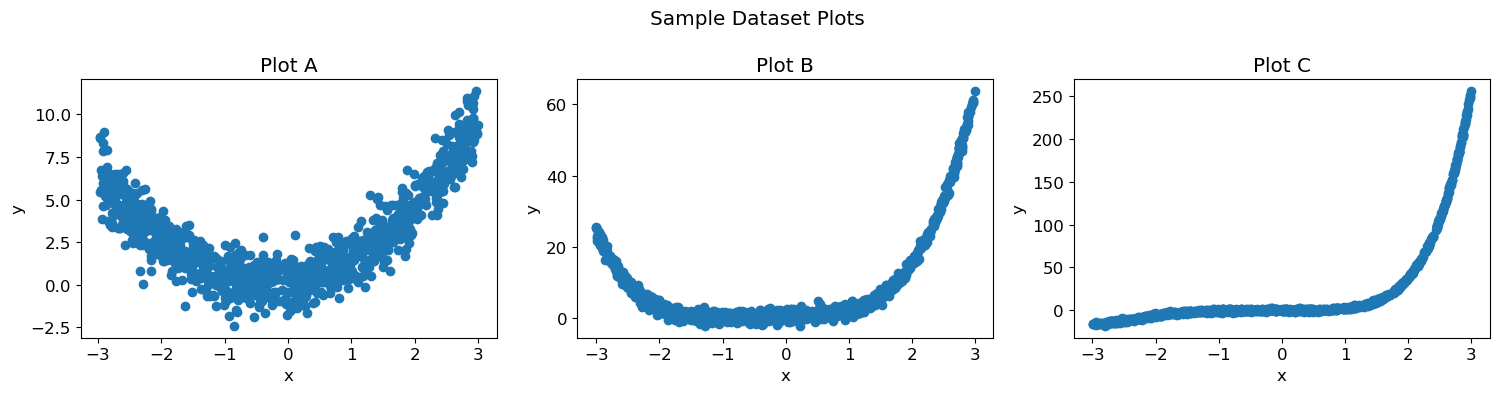

In [23]:
plt.figure(figsize=(15, 4))
# plot for polynomial_dataset(2, 1000)
plt.subplot(1,3,1)
plt.scatter(x_a, y_a)
plt.title('Plot A')
plt.xlabel('x')
plt.ylabel('y')

# plot for polynomial_dataset(4, 1000)
plt.subplot(1,3,2)
plt.scatter(x_b, y_b)
plt.title('Plot B')
plt.xlabel('x')
plt.ylabel('y')

# plot for polynomial_dataset(6, 1000)
plt.subplot(1,3,3)
plt.scatter(x_c, y_c)
plt.title('Plot C')
plt.xlabel('x')
plt.ylabel('y')

plt.suptitle('Sample Dataset Plots')
plt.tight_layout()
plt.show()

To test out if the function is working properly, We plot the generated data into a scatter plot. We can see that:

The first plot we fed the function a polynomial degree of 2. The data points are generating an almost parabola shape, and the epsilon term is adding some noise. The second plot is a higher polynomial degree(k=4), showing a steeper upward curve, the last plot is showing an even steeper and moving upward rapidly(k=6).

We can conclude that the dataset generator function is working as expected: it is producing correct polynomial degree dataset, with the bias term adding variability.

## 2. Generate three toy datasets using your function: a linear, a quadratic, and cubic dataset. Use n samples = 1000. Make sure you have a training and test set for each dataset.

In [24]:
# random seed for reproducibility
np.random.seed(42)
# creating a linear, quadratic, and cubic dataset.
x_linear, y_linear = polynomial_dataset(1, 1000)
x_quad, y_quad = polynomial_dataset(2, 1000)
x_cubic, y_cubic = polynomial_dataset(3, 1000)
datasets = {}
dataset_list = [
    ('linear', x_linear, y_linear),
    ('quadratic', x_quad, y_quad),
    ('cubic', x_cubic, y_cubic)
]
# spliting each dataset into a train and test set and storing them into a dictionary
for dataset, x, y in dataset_list:
    X_train, X_test, y_train, y_test = train_test_split(x, y, test_size = 0.20, random_state=42)
    datasets[dataset] = {'X_train': X_train, 'X_test': X_test, 'y_train': y_train, 'y_test': y_test}

    print(f'{dataset} dataset:')
    print(f'X_train: {len(X_train)}')
    print(f'y_train: {len(y_train)}')
    print(f'X_test: {len(X_test)}')
    print(f'y_test: {len(y_test)}')


linear dataset:
X_train: 800
y_train: 800
X_test: 200
y_test: 200
quadratic dataset:
X_train: 800
y_train: 800
X_test: 200
y_test: 200
cubic dataset:
X_train: 800
y_train: 800
X_test: 200
y_test: 200


We generate the 3 different types of datasets, linear, quadratic and cubic and we split each dataset into a 80-20 train and test set for X and y. After running, we print out the lengths for each dataset. We can see from the results, the split did correctly split them into an 80-20 train test split. We then check if the populated datasets are of linear, quadratic and cubic polynomial form.

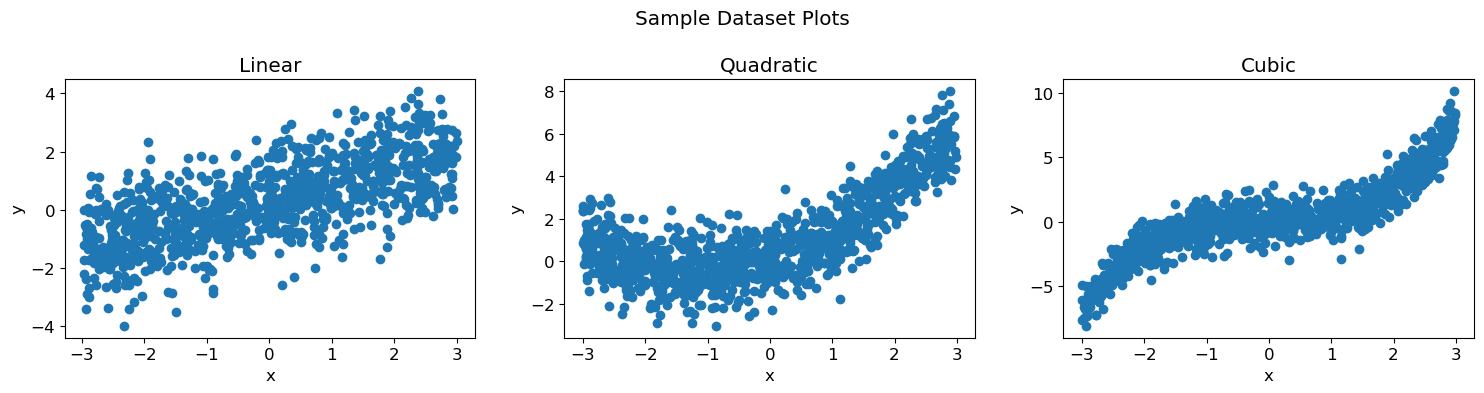

In [25]:
plt.figure(figsize=(15, 4))
# plot for polynomial_dataset(1, 1000)
plt.subplot(1,3,1)
plt.scatter(x_linear, y_linear)
plt.title('Linear')
plt.xlabel('x')
plt.ylabel('y')

# plot for polynomial_dataset(2, 1000)
plt.subplot(1,3,2)
plt.scatter(x_quad, y_quad)
plt.title('Quadratic')
plt.xlabel('x')
plt.ylabel('y')

# plot for polynomial_dataset(3, 1000)
plt.subplot(1,3,3)
plt.scatter(x_cubic, y_cubic)
plt.title('Cubic')
plt.xlabel('x')
plt.ylabel('y')

plt.suptitle('Sample Dataset Plots')
plt.tight_layout()
plt.show()

We check if the plotted data is correct. We can see from the scatterplot:

The first plot is a linear plot, given that we fed the random polynomial dataset function a polynomial degree of 1. The data points form almost a straight line. The bias term is adding some noise, hence why the points are not close together. Overall, the dataset remains to show a linear trend. This shows the random polynomial dataset function correctly produces a dataset with a first degree polynomial relationship.

The second plot is a quadratic plot, since we fed the function a polynomial degree of 2. The data points are generating a almost parabola shape, and the bias term is adding some noise, which results to the points not being tightly compact with each other. Over all, the function is able to produce a quadratic dataset when we feed in a polynomial degree of 2.

Lastly, feeding in the function a polynomial degree of 3, we are able to produce a plot that is almost s-shaped. The noise added some variability, but the shape is still similar to s-shaped. The function is still able to accurately produce a cubic, non-linear dataset.

We can conclude that the dataset generator function created the correct datasets of different polynomial degrees.

## 3. Experiment with fitting a sklearn.svm.SVR model to each of the three datasets using kernel=’linear’, kernel=’poly’ and kernel=’rbf’.

In [26]:
# setting the kernels that will be used
kernels = ['linear', 'poly', 'rbf']
# dictionary to store each kernel for each dataset
svr_models = {}
# import SVR from sklearn
from sklearn.svm import SVR
# applying svr using each kernel to each dataset and storing them into a dictionary
for dataset, data in datasets.items():
    X_train = data['X_train']
    y_train = data['y_train']
    
    svr_models[dataset] = {}
    for kern in kernels:
        model = SVR(kernel=kern)
        model.fit(X_train, y_train)
        svr_models[dataset][kern] = model

### (a) Show plots of the fitted regression function for each kernel and each dataset.

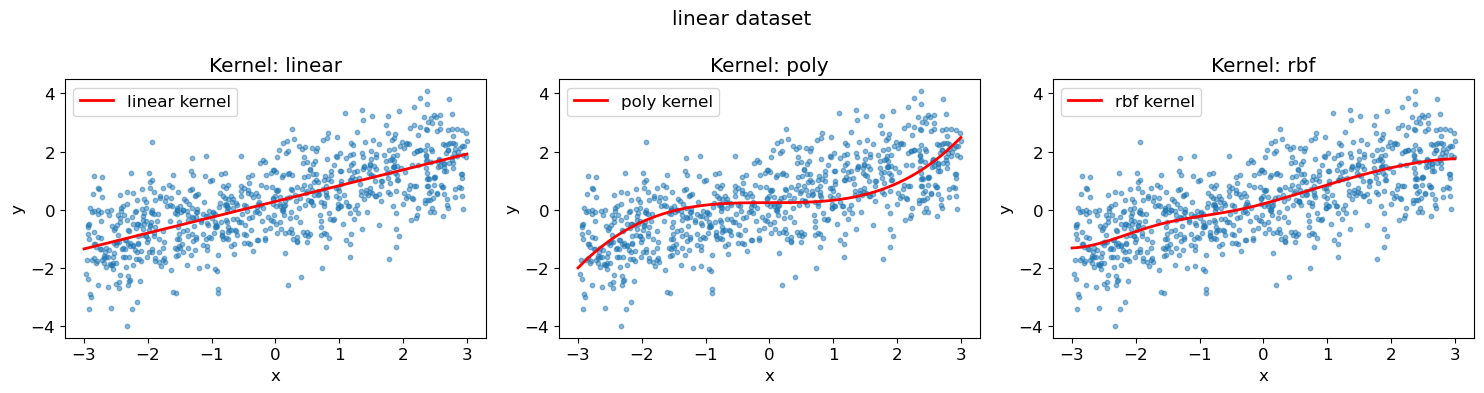

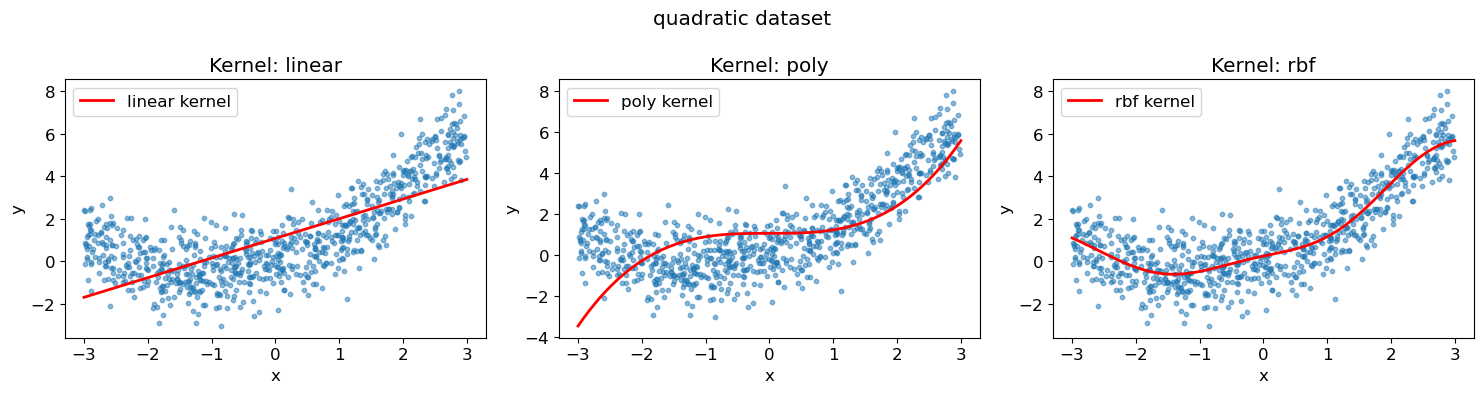

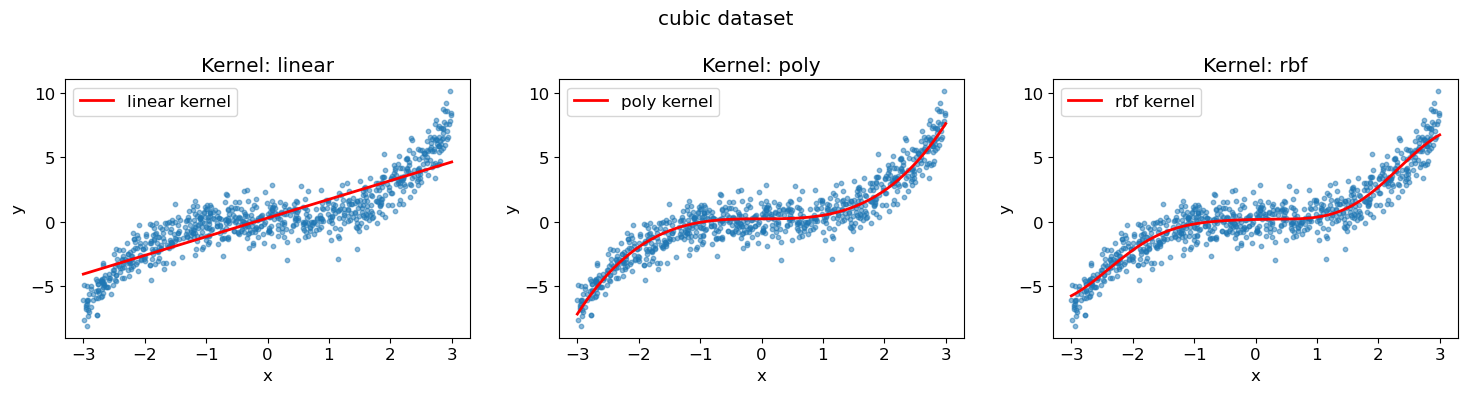

In [27]:
# plotting all the fitted model for each dataset
x_plot = np.linspace(-3, 3, 500).reshape(-1, 1)
for dataset, data in datasets.items():
    plt.figure(figsize=(15, 4))
    plt.suptitle(f'{dataset} dataset')
    X_train = data['X_train']
    y_train = data['y_train']
    # loop through each kernels and plot the fitted line
    for i, kernel in enumerate(kernels):
        svr = svr_models[dataset][kernel]
        y_pred = svr.predict(x_plot)

        plt.subplot(1, 3, i+1)
        plt.scatter(X_train, y_train, alpha=0.5, s=10)
        plt.plot(x_plot, y_pred, color = 'red', linewidth=2, label=f'{kernel} kernel')
        plt.xlabel('x')
        plt.ylabel('y')
        plt.title(f'Kernel: {kernel}')
        plt.legend()

    plt.tight_layout()
    plt.show()

### (b) Comment on the results. Are they what you expected?

For the Linear dataset:
kern = 'linear', it seems to me that it fits perfectly in the dataset, as it passes through the x and y in a straight line, given it is a linear dataset.
kern = 'poly', it seems to be a bit more flexible as there are points where it seems to overestimate and underestimate the data.
kern = 'rbf', it seems to be also flexible, but not as flexible as 'poly', but still captures the general trend.

For the quaduatric dataset:
kern = 'linear', it seems to underfit the quadratic dataset.
kern = 'poly', it seems to be more flexible and it does seem as it is trying to fit the data better than 'linear', though it is a bit too flexible even for a quadratic dataset.
kern = 'rbf', it perfectly fits the data as it captures all the points perfectly.

For the cubic dataset:
kern = 'linear', similar to the quadratic dataset, kernel = 'linear' is severly underfitting the data. It does not fit the data perfectly.
kern = 'poly', it seems to be a bit more flexible as it is fitting the data perfectly.
kern = 'rbf', similar to kern = 'poly', it is flexible and fitting the data perfectly.

The results are to be expected since:
kern = 'linear', is designed to model a linear relationship, thus why it performs the best on the linear dataset compared to the other kernels.
kern = 'poly', is designed to model non-linear relationships, thus why it performs well on quadratic and fits perfectly on cubic, since poly uses a degress of 3.
kern = 'rbf', is also designed to model complex non-linear relationships, thus why is performs the best for non-linear relationships quadratic and cubic, while it's too flexible for linear datasets.

## 4. Perform grid-search with k-fold cross-validation (k = 5) on at least three hyperparameters (including kernel) with two different values each (23 = 8 total combinations) for your cubic dataset.

In [28]:
# importing the SVR, DridSearchCV and KFold functions
from sklearn.svm import SVR
from sklearn.model_selection import GridSearchCV, KFold
# calling the cubic dataset as the main dataset
for data_name, dataset in datasets.items():
    if data_name == 'cubic':
        X_train = dataset['X_train']
        X_test = dataset['X_test']
        y_train = dataset['y_train']
        y_test = dataset['y_test']
# applying gridsearch to the SVR model with 3 different hyperparameters with 2 values for each
model = GridSearchCV(SVR(),
                  param_grid = {'epsilon':[0.01, 0.1],'C': [1, 10], 'kernel':['linear', 'rbf']},
                   cv = KFold(n_splits = 5, shuffle=True, random_state=42),
                   refit = True
                  )
# training the model and applying gridsearch
model.fit(X_train, y_train)

GridSearchCV(cv=KFold(n_splits=5, random_state=42, shuffle=True),
             estimator=SVR(),
             param_grid={'C': [1, 10], 'epsilon': [0.01, 0.1],
                         'kernel': ['linear', 'rbf']})

### (a) What hyperparameters did you choose? How many models did you fit in total?

I decided to choose:

'C': 0.1, 10
'epsilon': 0.01, 0.1
'kernel': linear, rbf

because given a cubic dataset, I chose hyperparameters that allow the model perfrom well on linear and non-linear data. And, given that grid search is used to tune the hyperparameters, it should choose the hyperparameters that performs well on a cubic/non-linear dataset.

Grid Search is a a way to apply hyperparameter tuning, it takes into account all possible combinations of hyper parameters and apply Cross Validation, then chooses the best hyperparameters. So first, it takes into account all possible combinations of hyperparameters and given that we have 3 hyperparameters with 2 values for each, we would have total combination of 8($2^2$) hyperparameters. Next, the Grid Dearch function will apply cross-validation, which splits the training data into k-folds and then trains and evaluates a model using a different combination of such set. Since we are to split the data into 5 folds, each combination will then use 5 different folds to evaluate which is the best hyperparameter. Thus, we would fit 40 ($8x5$) models.

### (b) Present your results for the optimal hyperparameter combination.

In [29]:
# call out the best hyperparameters from the gridsearch function
print('The optimal hyperparameters based on GridSearchCV is:', model.best_params_)

The optimal hyperparameters based on GridSearchCV is: {'C': 10, 'epsilon': 0.1, 'kernel': 'rbf'}


## 5. Given your optimal model found in the previous step, evaluate your model on the test set. Present your results.

In [30]:
# importing mean square error function
from sklearn.metrics import mean_squared_error
# get the optimised model and predicting y based on the test set
best_model = model.best_estimator_
y_pred = best_model.predict(X_test)
# comparing the optimised best model with other kernels
linear_kernel = SVR(kernel='linear')
linear_model = linear_kernel.fit(X_train, y_train)
polynomial_kernel = SVR(kernel='poly')
polynomial_model = polynomial_kernel.fit(X_train, y_train)
y_pred_lin = linear_model.predict(X_test)
y_pred_poly = polynomial_model.predict(X_test)
# calculating MSE
mse_linear_svr = mean_squared_error(y_test, y_pred_lin)
mse_polynomial_svr = mean_squared_error(y_test, y_pred_poly)
mse_best_svr = mean_squared_error(y_test, y_pred)
print('The Mean Square Error of the linear model is:', mse_linear_svr)
print('The Mean Square Error of the polynomial model is:', mse_polynomial_svr)
print('The Mean Square Error of the optimal model is:', mse_best_svr)

The Mean Square Error of the linear model is: 1.9854080824850309
The Mean Square Error of the polynomial model is: 0.9516655517644527
The Mean Square Error of the optimal model is: 0.9495995146368071


Given that we have a Regression Support Vector Machine, in order for us to evaluate the model, we will need to evaluate it's cost function. The cost function for a regression is the Mean Square Error, which measures how far the model predicted to the actual predictions, we would want a small MSE, which indicates the model is accurately predicting the actual values. We were able to pull a MSE of 0.9496, which is very small, this suggests the model's predictions are close to the real value, and is only off by $\sqrt{0.9496} = 0.974$, this slight miscalculation is most likely due to the noise generated into the dataset from the toy polynomial dataset generator function.

To further support this, I populated the MSE scores for when the kernel is linear and polyunomial. We can see that the linear kernel model has a very high MSE error, indicating the linear model is not optimal in it's predictions. However, the polynomial kernel model seems to have a similar MSE score to the optimal model, though it has a slightly higher MSE in general, though compared to the linear kernel, polynomial fits the data well. This suggests that the polynomial can fit the cubic nature of the dataset, but not as optimal as the model with the best hyperparameters.

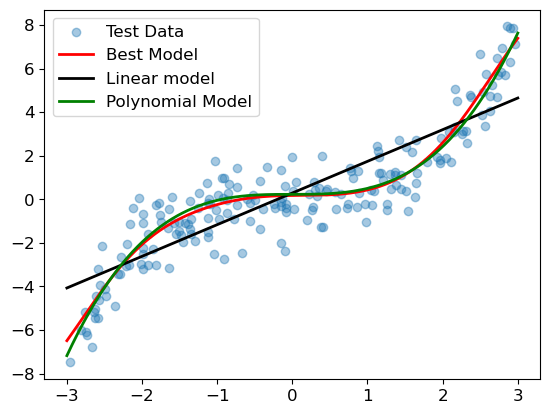

In [31]:
# plotting the fitted line
x_plot = np.linspace(-3,3,1000).reshape(-1,1)
y_pred = best_model.predict(x_plot)
y_pred_lin = linear_model.predict(x_plot)
y_pred_poly = polynomial_model.predict(x_plot)
plt.scatter(X_test, y_test, alpha = 0.4, label='Test Data')
plt.plot(x_plot, y_pred, color='red', linewidth=2, label='Best Model')
plt.plot(x_plot, y_pred_lin, color='black', linewidth=2, label = 'Linear model')
plt.plot(x_plot, y_pred_poly, color='green', linewidth=2, label = 'Polynomial Model')
plt.legend()
plt.show()

We further confirm the results with the plot, the optimal SVM Regression model is following the nonlinear pattern of the dataset perfectly, visually showing the optimal model has captured the cubic dataset fairly well. In contrast, the linear kernel model fails to capture the nonlinearity of the cubic dataset and underfits it. This is clearly shown  by the straight line it has produced. The polynomial model provides a better fit compared to the linear model, and is following the overall non-linearity of the dataset well, but is still does not match the accuracy of the optimal model. Overall, the visual plot and MSE values confirm that the tuned model from GridSearchCV provides the best model for the cubic dataset.

# III. Conclusion

In conclusion, we were able to implement a softmax regression function and compare it to sklearn's logistic regression. The results show that the manual softmax was able to perform reasonably well, sklearn's logistic regression was expected to slightly outperform the manual implementation of the softmax regression, which is likely due to the different optimisation methods used. In part 2, we were able to apply GridSearchCV to find the most optimal hyperparameters to fit the cubic dataset, achieving a low MSE score and a fitted line that fits well on the cubic dataset. Overall, we can see that although manual implementations can give us a good understanding on the underlying mathematics of the machine learning algorithms, sklearn libraries' algorithms seem to be even more well optimised and that hyperparameter tuning is essential when we need to find the optimal settings for out machine learning algorithm.